Public cible : 

In [55]:
pip install pandas matplotlib seaborn


[notice] A new release of pip is available: 25.0 -> 25.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [56]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
data = pd.read_csv("googleplaystore_cleaned.csv")

Répartition des Applications selon le Content Rating

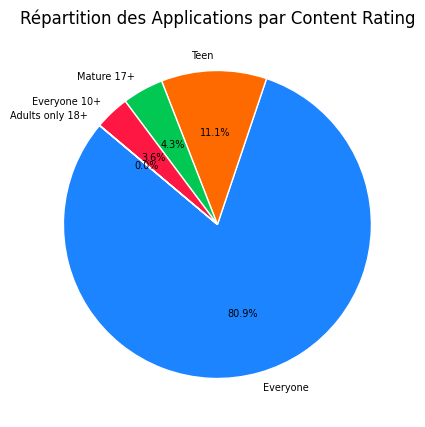

In [58]:
google_play_colors =  ["#1D84FF", "#FF6A00", "#00C853", "#FF1744", "#FFFF33"]


content_rating_counts = data["Content Rating"].value_counts()

plt.figure(figsize=(8, 5))
plt.pie(content_rating_counts.values, 
        labels=content_rating_counts.index, 
        autopct=lambda pct: f'{pct:.1f}%' if pct > 0 else '',  
        colors=google_play_colors, 
        startangle=140, 
        wedgeprops={'edgecolor': 'white'},
        textprops={'fontsize': 7})  

plt.title("Répartition des Applications par Content Rating")


plt.show()


App payantes ou gratuites selon Content Rating 

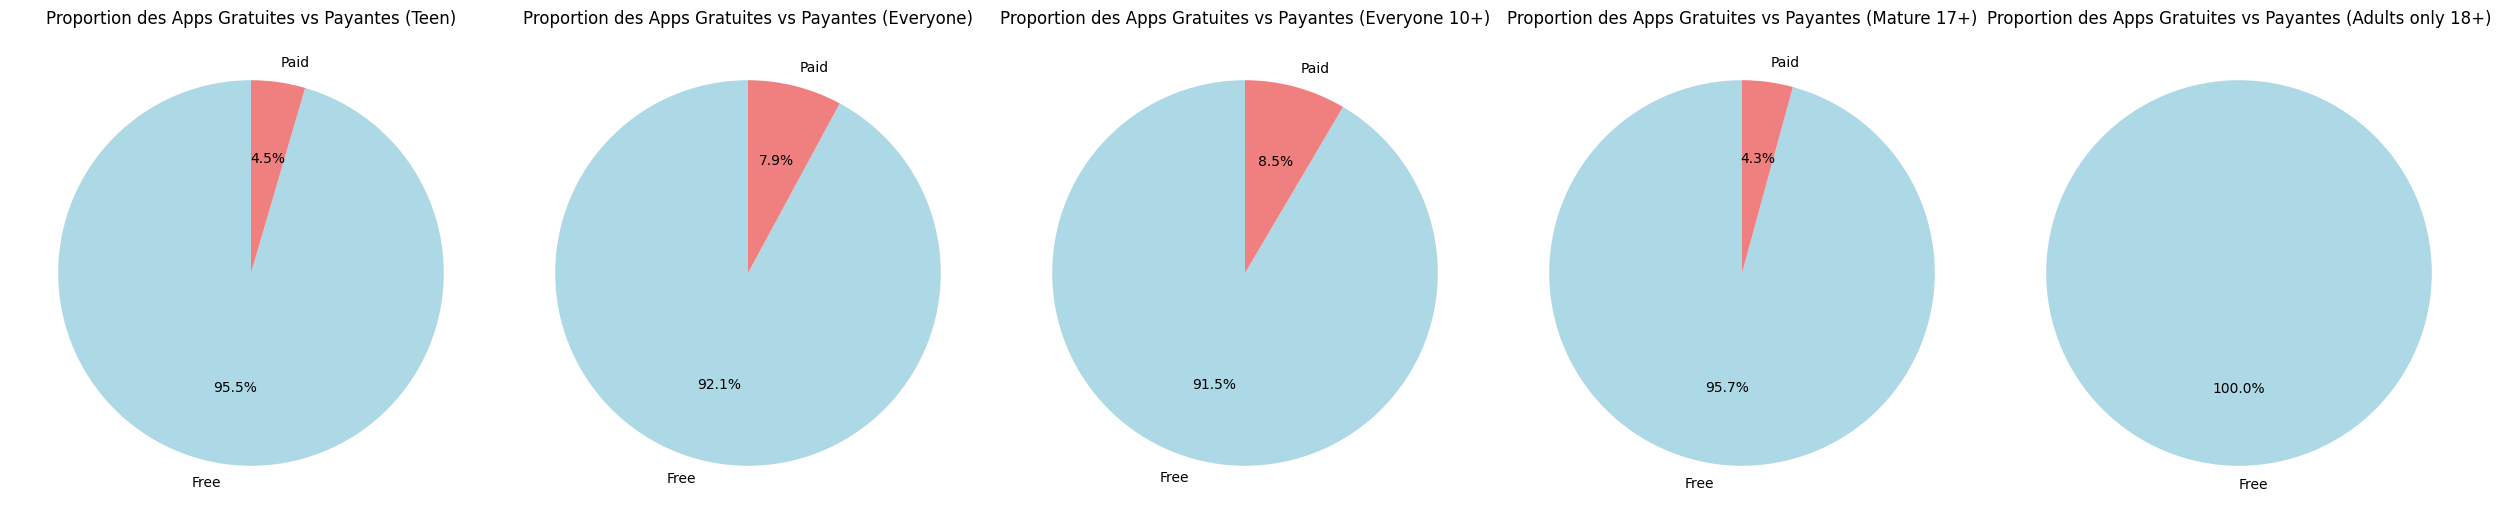

In [59]:
teen_apps = data[data["Content Rating"] == "Teen"]
everyone_apps = data[data["Content Rating"] == "Everyone"]
everyone_10_apps = data[data["Content Rating"] == "Everyone 10+"]
mature_17_apps = data[data["Content Rating"] == "Mature 17+"]
adults_only_18_apps = data[data["Content Rating"] == "Adults only 18+"]

nb_app_paid_teen = teen_apps["Price"].apply(lambda x: "Free" if x == 0 else "Paid").value_counts()
nb_app_paid_everyone = everyone_apps["Price"].apply(lambda x: "Free" if x == 0 else "Paid").value_counts()
nb_app_paid_everyone_10 = everyone_10_apps["Price"].apply(lambda x: "Free" if x == 0 else "Paid").value_counts()
nb_app_paid_mature_17 = mature_17_apps["Price"].apply(lambda x: "Free" if x == 0 else "Paid").value_counts()
nb_app_paid_adults_only_18 = adults_only_18_apps["Price"].apply(lambda x: "Free" if x == 0 else "Paid").value_counts()


fig, axes = plt.subplots(1, 5, figsize=(25, 6))

colors = ["lightblue", "lightcoral"]


axes[0].pie(nb_app_paid_teen, labels=nb_app_paid_teen.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[0].set_title("Proportion des Apps Gratuites vs Payantes (Teen)")

axes[1].pie(nb_app_paid_everyone, labels=nb_app_paid_everyone.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[1].set_title("Proportion des Apps Gratuites vs Payantes (Everyone)")

axes[2].pie(nb_app_paid_everyone_10, labels=nb_app_paid_everyone_10.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[2].set_title("Proportion des Apps Gratuites vs Payantes (Everyone 10+)")

axes[3].pie(nb_app_paid_mature_17, labels=nb_app_paid_mature_17.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[3].set_title("Proportion des Apps Gratuites vs Payantes (Mature 17+)")

axes[4].pie(nb_app_paid_adults_only_18, labels=nb_app_paid_adults_only_18.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[4].set_title("Proportion des Apps Gratuites vs Payantes (Adults only 18+)")

plt.tight_layout()
plt.show()



Répartition des notes selon le Content Rating

/var/folders/kj/cf4lkqr54pb_nq_6f472s9400000gn/T/ipykernel_10541/2036824578.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Content Rating', y='Rating', palette=google_play_colors)


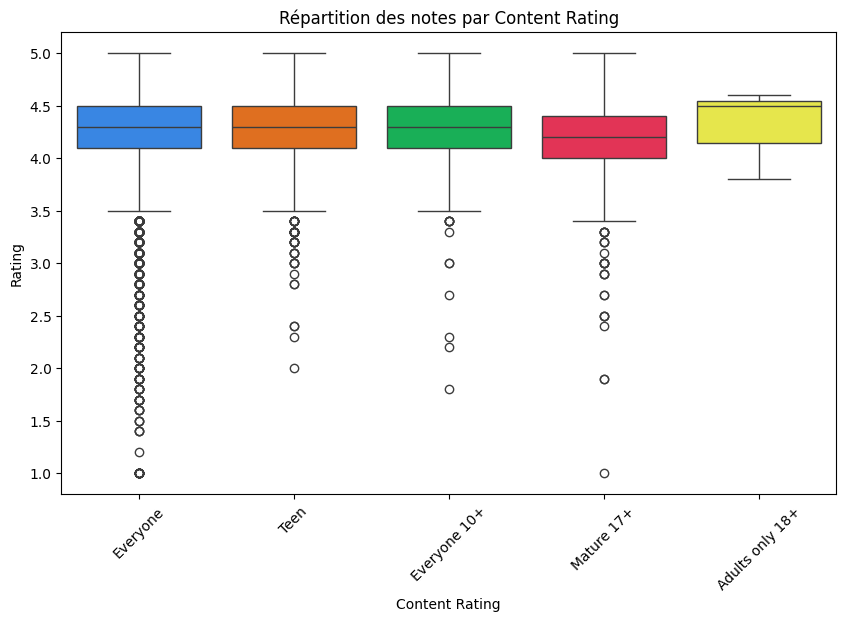

In [60]:

google_play_colors =  ["#1D84FF", "#FF6A00", "#00C853", "#FF1744", "#FFFF33"]

plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='Content Rating', y='Rating', palette=google_play_colors)
plt.title("Répartition des notes par Content Rating")
plt.xticks(rotation=45)
plt.show()


Nombre moyen d'installations selon le content Rating

/var/folders/kj/cf4lkqr54pb_nq_6f472s9400000gn/T/ipykernel_10541/2419946760.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=installs_avg.index, y=installs_avg.values, palette = google_play_colors)


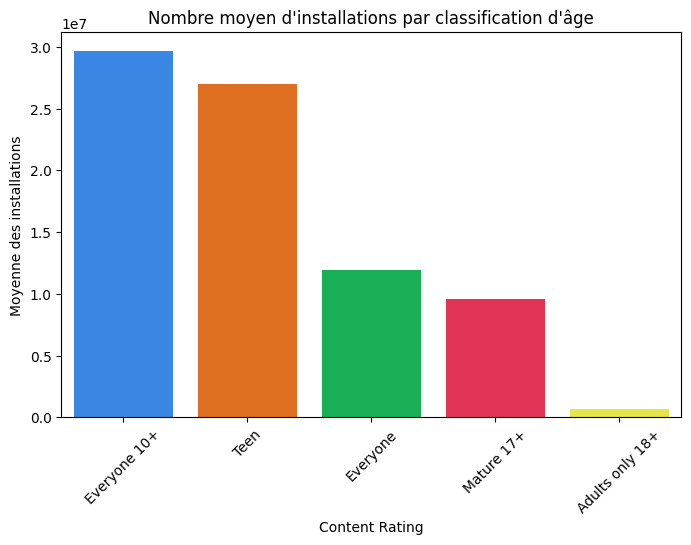

In [61]:
google_play_colors =  ["#1D84FF", "#FF6A00", "#00C853", "#FF1744", "#FFFF33"]


installs_avg = data.groupby("Content Rating")["Installs"].mean().sort_values(ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x=installs_avg.index, y=installs_avg.values, palette = google_play_colors)
plt.xticks(rotation=45)
plt.xlabel("Content Rating")
plt.ylabel("Moyenne des installations")
plt.title("Nombre moyen d'installations par classification d'âge")
plt.show()


Nombre d'applications et installations moyennes par content Rating

/var/folders/kj/cf4lkqr54pb_nq_6f472s9400000gn/T/ipykernel_10541/3301315593.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_installs.index, y=avg_installs.values, ax=ax1, palette=google_play_colors, alpha=0.7)


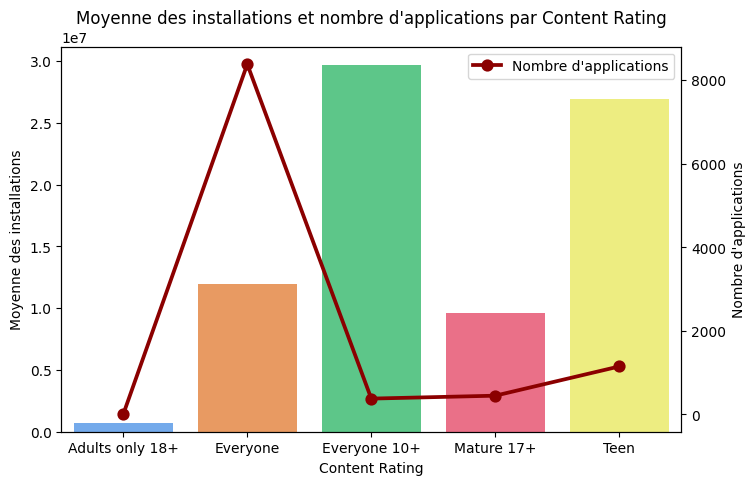

In [62]:
google_play_colors = ["#1D84FF", "#FF6A00", "#00C853", "#FF1744", "#FFFF33"]


app_count = data["Content Rating"].value_counts()
avg_installs = data.groupby("Content Rating")["Installs"].mean()


fig, ax1 = plt.subplots(figsize=(8, 5))

sns.barplot(x=avg_installs.index, y=avg_installs.values, ax=ax1, palette=google_play_colors, alpha=0.7)
ax1.set_ylabel("Moyenne des installations")


ax2 = ax1.twinx()
sns.pointplot(x=app_count.index, y=app_count.values, ax=ax2, color="darkred", marker="o", linestyle="-", label="Nombre d'applications")

ax1.set_xlabel("Content Rating")
ax2.set_ylabel("Nombre d'applications")
plt.title("Moyenne des installations et nombre d'applications par Content Rating")
plt.xticks(rotation=45)

plt.show()

In [63]:
adults_only_count = data[data["Content Rating"] == "Adults only 18+"]

print(adults_only_count) 

                                           App Category  Rating  Reviews  \
265   Manga Master - Best manga & comic reader   COMICS     4.6    24005   
2669         DraftKings - Daily Fantasy Sports   SPORTS     4.5    50017   
5965                               Manga Books   COMICS     3.8     7326   

         Size  Installs  Type  Price   Content Rating  Last Updated  \
265    4900.0    500000  Free    0.0  Adults only 18+          2018   
2669  41000.0   1000000  Free    0.0  Adults only 18+          2018   
5965      NaN    500000  Free    0.0  Adults only 18+          2018   

             Current Ver         Android Ver  
265              1.1.7.0          4.1 and up  
2669            3.21.324          4.4 and up  
5965  Varies with device  Varies with device  


In [64]:
teen_or_10plus = data[data["Content Rating"].isin(["Everyone"])]

category_counts = teen_or_10plus["Category"].value_counts()

category_counts.head()

Category
FAMILY          1502
TOOLS            835
GAME             595
BUSINESS         412
PRODUCTIVITY     396
Name: count, dtype: int64